In [23]:
import numpy as np
import matplotlib.pyplot as plt
import astropy.units as u
import astropy.constants as const
import h5py

import matplotlib.colors as mcolors
import matplotlib.cm as cm

import flash_amr_tools
from tqdm import tqdm

flash_output_dir = "/home/watanabe/Projects/meerkat_bowshocks/outputs"
fig_dir = "/home/watanabe/Projects/meerkat_bowshocks/figures"
data_dir = "/home/watanabe/Projects/meerkat_bowshocks/meerkat_nrfs/meerkat_nrfs/data/"

In [24]:
# simulation output file
sim_file = "BowShock_HarpISM_m20/starISM_hdf5_plt_cnt_0023"

# parameters set in this file
mstar = 20 * u.M_sun
vstar = 30 * (u.km / u.s)
env_name = "ISM"
kappa_10 = 3e26 * (u.cm**2 / u.s)

In [25]:
# constants used
mp = const.m_p.cgs
me = const.m_e.cgs
c = const.c.cgs

First read in external data

In [26]:
with h5py.File(f"{data_dir}/standoff_radius.h5", "r") as f:

    mstar_grid = f["mstar_grid"][()] * u.Msun
    vstar_grid = f["vstar_grid"][()] * u.km / u.s

    R0_grid = f[env_name]["R0_grid"][()] * u.cm

mstar_idx = np.digitize(mstar, mstar_grid, right=True)
vstar_idx = np.digitize(vstar, vstar_grid, right=True)

R0 = R0_grid[mstar_idx, vstar_idx].to(u.pc)
print(f"Stand-off radius: {R0.to(u.pc):.3f}")

with h5py.File(f"{data_dir}/steady_state_spectrum_thr.h5", "r") as f:
    log10_R0_grid = f["log10_R0_grid"][()]
    log10_vel_grid = f["log10_vel_grid"][()]
    log10_kappa10_grid = f["log10_kappa10_grid"][()]
    log10_dens_grid = f["log10_dens_grid"][()]
    alpha_inj_grid = f["alpha_inj_grid"][()]
    log10_pprot_grid = f["log10_pprot_grid"][()]
    steady_state_mom_grid_full = f["steady_spect_mom_grid"][()]

steady_state_mom_grid = steady_state_mom_grid_full[:,:,np.digitize(np.log10(kappa_10.value), log10_kappa10_grid, right=True), np.digitize(np.log10(R0.value), log10_R0_grid, right=True), :,:]

Stand-off radius: 1.294 pc


To calculate, we need the following (Pfrommer et al 2022)

- spectral index calculated using mach number
- number of electrons contributing to synchrotron emission, calculated by ratios
  - need values of d and lambda from density & velocity
- los magnetic field
- observed synchrotron frequency

For the frequency, we use the observed synchrotron frequency from meerkat

In [27]:
synch_freq = 1.28 * u.GHz   # synchrotron frequency from telescope

First get CR electrons contributing to synchrotron emission. We calculate this using the synchrotron kernel & the critical frequency, integrating over all electron momenta.

Momenta can be converted from proton -> electron by energy scaling factor.

In [28]:
def synch_kernel(x):
    '''As in Aharonian et al. 2010'''
    exp_factor = (1 + 0.884 * x**(2/3) + 0.471 * x**(4/3)) / (1 + 1.64 * x**(2/3) + 0.974 * x**(4/3))
    return 2.15 * x**(1/3) * (1 + 3.06 * x)**(1/6) * exp_factor * np.exp(-x)

def crit_freq(Blos, pele):
    '''Critical frequency as a function of magnetic field / microG and electron energy / GeV'''
    return 0.5 * (Blos / (1 * u.uG)) * (np.sqrt(1 + (pele / (me * c))**2) / 1e4)**2 * u.GHz

def ekin(p, m=const.m_p.cgs):
    '''kinetic energy of proton in GeV'''
    return (np.sqrt(p**2*c**2 + mp**2*c**4) - mp*c**2).to(u.GeV)

def pele(pprot):
    '''secondary electron momentum from pion loss as function of proton momentum'''
    return (np.sqrt((ekin(pprot) / 16 + me*c**2)**2 - me**2*c**4) / c).to(u.cm * u.g / u.s)

calculate the ratio

In [29]:
pprot_grid = (10.0**log10_pprot_grid * (u.cm * u.g / u.s))
pele_grid = pele(pprot_grid)

In [30]:
Blos_interp_grid = np.logspace(-10, -4, 100) * u.G

log10_ensynch_grid = np.zeros((len(alpha_inj_grid), len(log10_vel_grid), len(log10_dens_grid), len(Blos_interp_grid)))

encr_grid = np.trapz(y=4 * np.pi * (pprot_grid[:,None,None,None])**2 * ekin(pprot_grid[:,None,None,None]) * steady_state_mom_grid, x=pprot_grid, axis=0)

for ib, Blos in enumerate(Blos_interp_grid):
    nuc = crit_freq(Blos, pele_grid)
    synch_ker = synch_kernel((synch_freq / nuc).to_value(u.dimensionless_unscaled))

    nelesynch = np.trapz(y=4 * np.pi * (pele_grid[:,None,None,None])**2 * steady_state_mom_grid * synch_ker[:,None,None,None], x=pele_grid, axis=0)
    
    log10_ensynch_grid[...,ib] = np.log10((encr_grid / nelesynch).to_value(u.GeV))


# first interpolate the enratio grid
from scipy.interpolate import RegularGridInterpolator

f_log10ensynchratio = RegularGridInterpolator((alpha_inj_grid, log10_vel_grid, log10_dens_grid, Blos_interp_grid), log10_ensynch_grid)

Now compute it using output data

In [31]:
blist, brefs, bns = flash_amr_tools.get_true_blocks(f"{flash_output_dir}/{sim_file}")

minimum position of the region of interest:  [-1.54283879e+19 -7.71419395e+19 -3.85709698e+19]
maximum position of the region of interest:  [6.17135516e+19 7.71419395e+19 3.85709698e+19]
Finding all leaf blocks in given region
11160 11160
Biggest block has refinement level: 4
Highest refinement level in simulation: 6
Highest refinement level in selected box: 6
Extending region to fit amr structure at level 4.
Trying extended region given by including blocks whose center is not in predefined region but part of their block volume is.
bnx, bny, bnz:  8.0 16.0 8.0
Block shape:  (8, 16, 8)
Total number of blocks including parent blocks: 12608
Region extended to:	lower		upper
	x	-1.54283878e+19		+6.17135514e+19
	y	-7.71419381e+19		+7.71419381e+19
	z	-3.85709691e+19		+3.85709691e+19

Region center at:	+2.31425823e+19	+0.00000000e+00	+0.00000000e+00
Given center:		+2.31425818e+19	+0.00000000e+00	+0.00000000e+00


In [32]:
with h5py.File(f"{flash_output_dir}/{sim_file}", "r") as pf:
    shma_data = pf["shma"][()][blist]
    dens_data = pf["dens"][()][blist]
    encr_data = pf["encr"][()][blist]
    magz_data = pf["magz"][()][blist]
    vel_data = [pf["velx"][()][blist], pf["vely"][()][blist], pf["velz"][()][blist]] 
    ref_lvl = pf["refine level"][()][blist]
    bbox = pf["bounding box"][()][blist]
    bsize = pf["block size"][()][blist]

low_cor, up_cor = bbox[0,:,0], bbox[-1,:,1]

extent = ([low_cor[0], up_cor[0], low_cor[1], up_cor[1]] * u.cm).to_value(u.pc)

4.0079675 10.0


Text(0, 0.5, 'Injection Index $\\alpha_\\mathrm{inj}$')

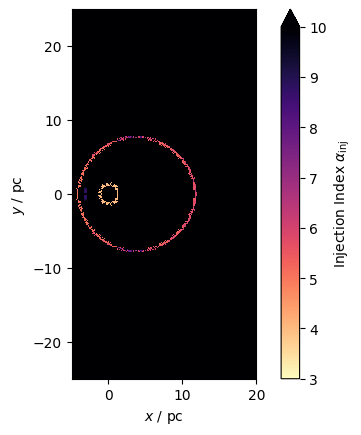

In [33]:
gam = 5/3

xs_data = (gam + 1) * shma_data**2 / (2 + (gam - 1) * shma_data**2)
alpha_inj_data = 3 * xs_data / (xs_data - 1)

# force minimal and maximal values
alpha_inj_data[alpha_inj_data < 4] = 10
alpha_inj_data[alpha_inj_data >= 10] = 10

print(alpha_inj_data.min(), alpha_inj_data.max())

# %reset_selective -f "shma_data"
# %reset_selective -f "xs_data"

alpha_inj_sl = flash_amr_tools.get_slice(alpha_inj_data, pos=0.0, axis=2, ref_lvl=ref_lvl, bbox=bbox, bsize=bsize, brefs=brefs, bns=bns)

# plot
fig, ax = plt.subplots()
norm = mcolors.Normalize(vmin=3, vmax=10, clip=True)

im = ax.imshow(alpha_inj_sl.T, norm=norm, cmap=cm.magma_r, alpha=1.0, interpolation="none", extent=extent)

# labels
ax.set_xlabel("$x$ / pc")
ax.set_ylabel("$y$ / pc")

cb = fig.colorbar(im, ax=ax, extend='max')
cb.ax.set_ylabel(r"Injection Index $\alpha_\mathrm{inj}$")

LOS agnetic field

9.999999717180685e-10 G 1.9428148334554862e-06 G


Text(0, 0.5, '$B_\\mathrm{LOS}$')

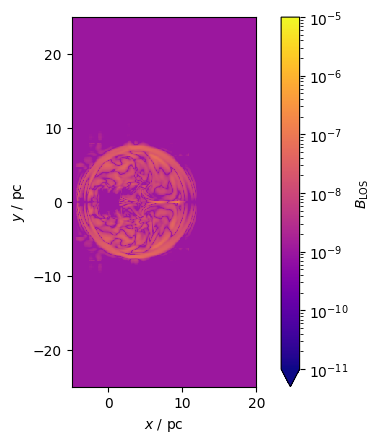

In [34]:
# # line-of-sight
# z_GC = 8.2e3 * u.pc  # distance to GC
# los_vec = (np.array([0, 0,z_GC.value]) * u.pc).value
# los_vec /= np.linalg.norm(los_vec)  # normalize
# print("Line-of-sight vector", los_vec)
Blos_data = np.abs(magz_data) * u.G
Blos_data[Blos_data < 1e-9 * u.G] = 1e-9 * u.G

print(Blos_data.min(), Blos_data.max())

Blos_sl = flash_amr_tools.get_slice(Blos_data, pos=0.0, axis=2, ref_lvl=ref_lvl, bbox=bbox, bsize=bsize, brefs=brefs, bns=bns)
 
# plot
fig, ax = plt.subplots()
norm = mcolors.LogNorm(vmin=1e-11, vmax=1e-5, clip=True)

im = ax.imshow(Blos_sl.T, norm=norm, cmap=cm.plasma, alpha=1.0, interpolation="none", extent=extent)

# labels
ax.set_xlabel("$x$ / pc")
ax.set_ylabel("$y$ / pc")

cb = fig.colorbar(im, ax=ax, extend='min')
cb.ax.set_ylabel("$B_\mathrm{LOS}$")

number of electrons in synchrotron emission

In [46]:
vel_mag_data = np.sqrt(vel_data[0]**2 + vel_data[1]**2 + vel_data[2]**2) * (u.cm / u.s)
ensynch_ratio = 10.0**f_log10ensynchratio((alpha_inj_data, np.log10(vel_mag_data.to_value(u.km/u.s)), np.log10(dens_data), Blos_data)) * u.GeV

print(ensynch_ratio.to(u.erg).min(), ensynch_ratio.to(u.erg).max())

57010.91128147668 erg 1.2255794018142279e+24 erg


In [35]:
nelesynch_data = ((encr_data * dens_data) * (u.erg / u.cm**3) / (10.0**f_log10ensynchratio((alpha_inj_data, np.log10(vel_mag_data.to_value(u.km/u.s)), np.log10(dens_data), Blos_data)) * u.GeV)).to(u.cm**-3)

In [36]:
nelesynch_data.min(), nelesynch_data.max()

(<Quantity 8.14893722e-40 1 / cm3>, <Quantity 4.02804698e-18 1 / cm3>)

Text(0, 0.5, '$n_\\mathrm{ele, synch}$')

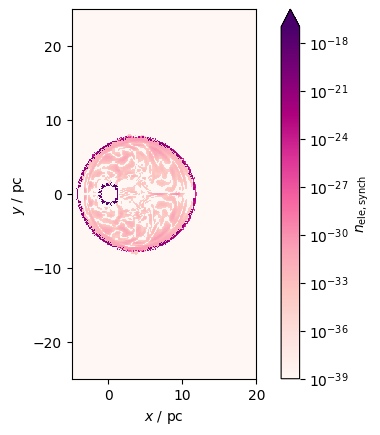

In [37]:
# plot
nelesynch_sl = flash_amr_tools.get_slice(nelesynch_data, pos=0.0, axis=2, ref_lvl=ref_lvl, bbox=bbox, bsize=bsize, brefs=brefs, bns=bns)

fig, ax = plt.subplots()
norm = mcolors.LogNorm(vmin=1e-39, vmax=1e-17, clip=True)

im = ax.imshow(nelesynch_sl.T, norm=norm, cmap=cm.RdPu, alpha=1.0, interpolation="none", extent=extent)

# labels
ax.set_xlabel("$x$ / pc")
ax.set_ylabel("$y$ / pc")

cb = fig.colorbar(im, ax=ax, extend='max')
cb.ax.set_ylabel("$n_\mathrm{ele, synch}$")

In [38]:
synch_emissiv_data = np.sqrt(3) * Blos_data.to(u.G)  / (me * c**2).to(u.GeV) * nelesynch_data
synch_emissiv_data.min(), synch_emissiv_data.max()
# %reset_selective -f "nelesynch_cube"

(<Quantity 2.76211383e-45 G / (cm3 GeV)>,
 <Quantity 1.83161965e-20 G / (cm3 GeV)>)

Text(0, 0.5, '$j_\\mathrm{synch}$ / (G / (erg / cm$^3$ e$^3$))')

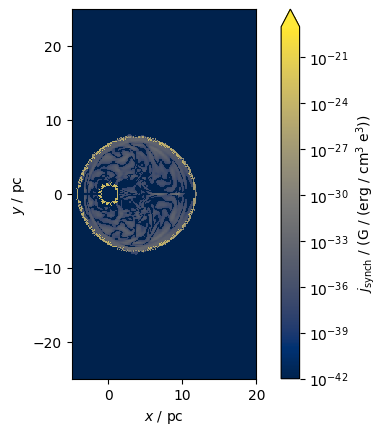

In [39]:
# plot
jsynch_sl = flash_amr_tools.get_slice(synch_emissiv_data, pos=0.0, axis=2, ref_lvl=ref_lvl, bbox=bbox, bsize=bsize, brefs=brefs, bns=bns)

fig, ax = plt.subplots()
norm = mcolors.LogNorm(vmin=1e-42, vmax=1e-19, clip=True)

im = ax.imshow(jsynch_sl.T, norm=norm, cmap=cm.cividis, alpha=1.0, interpolation="none", extent=extent)

# labels
ax.set_xlabel("$x$ / pc")
ax.set_ylabel("$y$ / pc")

cb = fig.colorbar(im, ax=ax, extend='max')
cb.ax.set_ylabel("$j_\mathrm{synch}$ / (G / (erg / cm$^3$ e$^3$))")

In [40]:
synch_intens_cube = flash_amr_tools.get_cdens(synch_emissiv_data.value, axis=2, ref_lvl=ref_lvl, bbox=bbox, bsize=bsize, brefs=brefs, bns=bns) * (u.G / (u.erg * u.cm**2))
# synch_intens_cube = np.trapz(y=synch_emissiv_cube, dx=(up_cor[2] - low_cor[2]) / synch_emissiv_cube.shape[2], axis=2) / (4 * np.pi)

In [41]:
synch_intens_cube.min(), synch_intens_cube.max()

(<Quantity 2.13126149e-25 G / (cm2 erg)>, <Quantity 0.03248915 G / (cm2 erg)>)

Text(0, 0.5, '$I_\\mathrm{synch}$ / (kg S / cm$^{-2}$)')

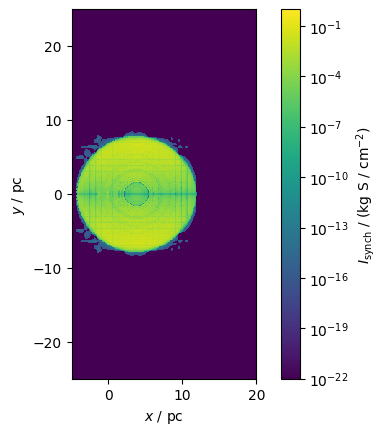

In [42]:
# plot
fig, ax = plt.subplots()
norm = mcolors.LogNorm(vmin=1e-22, vmax=1, clip=True)

im = ax.imshow(synch_intens_cube.value.T, norm=norm, cmap=cm.viridis, alpha=1.0, interpolation="none", extent=extent)

# labels
ax.set_xlabel("$x$ / pc")
ax.set_ylabel("$y$ / pc")

cb = fig.colorbar(im, ax=ax)
cb.ax.set_ylabel("$I_\mathrm{synch}$ / (kg S / cm$^{-2}$)")

Calculate luminosity

In [43]:
synch_emissiv_cube = flash_amr_tools.get_cube(synch_emissiv_data, ref_lvl=ref_lvl, bbox=bbox, bsize=bsize, brefs=brefs, bns=bns) * (u.G / (u.erg * u.cm**3))
dx = (up_cor[2] - low_cor[2]) / synch_emissiv_cube.shape[2] * u.cm
Lsynch = np.sum(synch_emissiv_cube * dx**3)
# print(Lsynch.si * const.e.si**3)

In [44]:
print(Lsynch)

3.296692957951431e+36 G / erg
